In [ ]:
import pandas as pd

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv("/auto-mpg.csv")
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [ ]:
df.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [ ]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82,2720,19.4,82,1,chevy s-10


In [ ]:
df.dtypes

,0
mpg,float64
cylinders,int64
displacement,float64
horsepower,object
weight,int64
acceleration,float64
model year,int64
origin,int64
car name,object


In [ ]:
numeric_columna = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

In [ ]:
print("\n Numeric Columns:")
print(numeric_columna)


 Numeric Columns:
['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model year', 'origin']


In [ ]:
print("Missing values before cleaning")
print(df.isnull().sum)

Missing values before cleaning
<bound method DataFrame.sum of        mpg  cylinders  displacement  horsepower  weight  acceleration  \
0    False      False         False       False   False         False   
1    False      False         False       False   False         False   
2    False      False         False       False   False         False   
3    False      False         False       False   False         False   
4    False      False         False       False   False         False   
..     ...        ...           ...         ...     ...           ...   
393  False      False         False       False   False         False   
394  False      False         False       False   False         False   
395  False      False         False       False   False         False   
396  False      False         False       False   False         False   
397  False      False         False       False   False         False   

     model year  origin  car name  
0         False   False  

In [ ]:
df['horsepower'] = pd.to_numeric(df['horsepower'],errors='coerce')
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

X = df[['mpg','cylinders','displacement','horsepower','weight','acceleration','model year']]

Scaler = MinMaxScaler()
X_scaled = Scaler.fit_transform(X)
print(X_scaled)


[[0.2393617  1.         0.61757106 ... 0.5361497  0.23809524 0.        ]
 [0.15957447 1.         0.72868217 ... 0.58973632 0.20833333 0.        ]
 [0.2393617  1.         0.64599483 ... 0.51686986 0.17857143 0.        ]
 ...
 [0.61170213 0.2        0.17312661 ... 0.19336547 0.21428571 1.        ]
 [0.50531915 0.2        0.13436693 ... 0.2869294  0.63095238 1.        ]
 [0.58510638 0.2        0.13178295 ... 0.31386447 0.67857143 1.        ]]


In [ ]:
encoder= LabelEncoder()
df['car name'] = encoder.fit_transform(df['car name'])
print(df[['car name']].head())

   car name
0        49
1        36
2       231
3        14
4       161


In [ ]:
X = df[['mpg','cylinders','displacement','horsepower','weight','acceleration','model year']]
Scaler = StandardScaler()
X_scaled = Scaler.fit_transform(X)
print(X_scaled)

[[-0.7064387   1.49819126  1.0906037  ...  0.63086987 -1.29549834
  -1.62742629]
 [-1.09075062  1.49819126  1.5035143  ...  0.85433297 -1.47703779
  -1.62742629]
 [-0.7064387   1.49819126  1.19623199 ...  0.55047045 -1.65857724
  -1.62742629]
 ...
 [ 1.08701694 -0.85632057 -0.56103873 ... -0.79858454 -1.4407299
   1.62198339]
 [ 0.57460104 -0.85632057 -0.70507731 ... -0.40841088  1.10082237
   1.62198339]
 [ 0.95891297 -0.85632057 -0.71467988 ... -0.29608816  1.39128549
   1.62198339]]


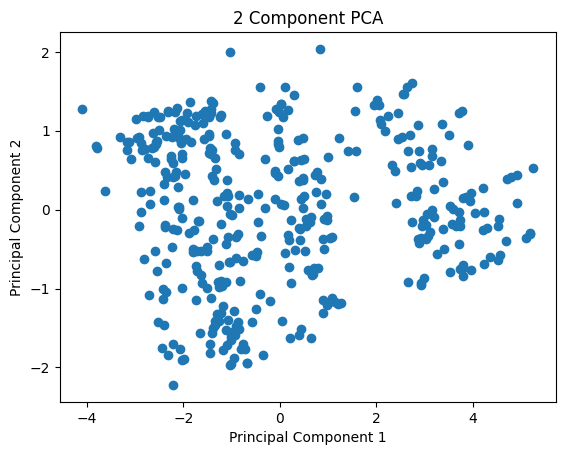

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X = df[['mpg','cylinders','displacement','horsepower','weight','acceleration','model year']]

X=X.fillna(X.mean())

Scaler = StandardScaler()
X_scaled=StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

plt.scatter(principal_components[:,0],principal_components[:,1])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2 Component PCA')
plt.show()